# Chess endgame classification

The complete experiment appears below as readable code cells. The same implementation is available in `experiment.py`. Model selection uses only training cross-validation. The final test set evaluates the selected pipeline.

In [1]:
from pathlib import Path
import os
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "code":
    PROJECT_ROOT = PROJECT_ROOT.parent
assert (PROJECT_ROOT / "data/kr-vs-kp.data").exists()
os.chdir(PROJECT_ROOT)
__file__ = str(PROJECT_ROOT / "code/experiment.py")

## Imports

In [2]:
from pathlib import Path
import json, hashlib, platform, sys, warnings
import numpy as np, pandas as pd, matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import scipy, sklearn, joblib
from scipy.stats import chi2_contingency
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV,
    cross_validate,
)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay,
    ConfusionMatrixDisplay,
)

## Data loading and quality checks

In [3]:
ROOT = Path(__file__).resolve().parent.parent
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)
features = "bkblk bknwy bkon8 bkona bkspr bkxbq bkxcr bkxwp blxwp bxqsq cntxt dsopp dwipd hdchk katri mulch qxmsq r2ar8 reskd reskr rimmx rkxwp rxmsq simpl skach skewr skrxp spcop stlmt thrsk wkcti wkna8 wknck wkovl wkpos wtoeg".split()
path = ROOT / "data/kr-vs-kp.data"
df = pd.read_csv(
    path, header=None, names=features + ["class"], dtype="string", keep_default_na=False
)
assert df.shape[1] == 37 and set(df["class"]) == {"won", "nowin"}
X = df[features].replace({"?": pd.NA, "": pd.NA})
y = (df["class"] == "won").astype(int)
duplicates = int(df.duplicated().sum())
dup_features = int(X.duplicated().sum())
conflict = int(df.groupby(features, dropna=False)["class"].nunique().gt(1).sum())
# Keep duplicated feature records together to prevent leakage if present. Standard split is used only when there are no duplicates.
if dup_features:
    raise ValueError(
        f"{dup_features} duplicate feature rows; inspect and use a group-aware split before proceeding"
    )
if conflict:
    raise ValueError(f"{conflict} conflicting labels")
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)

## Categorical exploration

In [4]:
# Full-data exploration is descriptive and does not guide features or tuning.
assoc = []
for col in features:
    tab = pd.crosstab(df[col], df["class"])
    chi2 = chi2_contingency(tab, correction=False)[0]
    n = tab.to_numpy().sum()
    denom = min(tab.shape[0] - 1, tab.shape[1] - 1)
    assoc.append(
        {
            "feature": col,
            "cramers_v": float(np.sqrt(chi2 / (n * denom))) if denom else 0.0,
            "categories": int(tab.shape[0]),
        }
    )
assoc = pd.DataFrame(assoc).sort_values("cramers_v", ascending=False)
assoc.to_csv(OUT / "categorical_associations.csv", index=False)
cat_counts = {c: df[c].value_counts(dropna=False).to_dict() for c in features}
missing = int(X.isna().sum().sum())

## Model definitions and parameter grids

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
models = {
    "Logistic Regression": (
        LogisticRegression(max_iter=3000, random_state=42),
        {"model__C": [0.1, 1, 10], "model__class_weight": [None, "balanced"]},
    ),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=42),
        {
            "model__max_depth": [5, 10, None],
            "model__min_samples_leaf": [1, 3],
            "model__class_weight": [None, "balanced"],
        },
    ),
    "KNN": (
        KNeighborsClassifier(),
        {"model__n_neighbors": [3, 5, 11], "model__weights": ["uniform", "distance"]},
    ),
    "Random Forest": (
        RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=1),
        {
            "model__max_depth": [None, 12],
            "model__min_samples_leaf": [1, 3],
            "model__class_weight": [None, "balanced"],
        },
    ),
    "Gradient Boosting": (
        GradientBoostingClassifier(random_state=42),
        {
            "model__n_estimators": [100, 150],
            "model__learning_rate": [0.05, 0.1],
            "model__max_depth": [2, 3],
        },
    ),
}

## Training cross validation and tuning

In [6]:
rows = []
fitted = {}
grids = {}
weighting = {}
for name, (est, grid) in models.items():
    pipe = Pipeline(
        [
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
            ("model", est),
        ]
    )
    baseline = cross_validate(
        pipe, Xtr, ytr, cv=cv, scoring={"f1": "f1", "recall": "recall"}, n_jobs=1
    )
    search = GridSearchCV(
        pipe, grid, cv=cv, scoring="f1", refit=True, n_jobs=1, return_train_score=False
    )
    search.fit(Xtr, ytr)
    cvdf = pd.DataFrame(search.cv_results_)
    cvdf[["params", "mean_test_score", "std_test_score", "rank_test_score"]].to_csv(
        OUT / (name.lower().replace(" ", "_") + "_grid.csv"), index=False
    )
    if "model__class_weight" in grid:
        w = {
            str(k): float(
                cvdf.loc[
                    (
                        cvdf["param_model__class_weight"].isna()
                        if k is None
                        else cvdf["param_model__class_weight"].eq(k)
                    ),
                    "mean_test_score",
                ].max()
            )
            for k in [None, "balanced"]
        }
        weighting[name] = w
    rows.append(
        {
            "model": name,
            "baseline_cv_f1": float(baseline["test_f1"].mean()),
            "baseline_cv_recall": float(baseline["test_recall"].mean()),
            "tuned_cv_f1": float(search.best_score_),
            "tuned_cv_sd": float(
                search.cv_results_["std_test_score"][search.best_index_]
            ),
            "best_params": str(search.best_params_),
        }
    )
    grids[name] = {
        "best_params": search.best_params_,
        "best_cv_f1": float(search.best_score_),
        "fold_sd": float(search.cv_results_["std_test_score"][search.best_index_]),
        "candidates": len(search.cv_results_["params"]),
    }
    fitted[name] = search.best_estimator_
    print(
        name,
        "baseline F1",
        round(baseline["test_f1"].mean(), 4),
        "tuned F1",
        round(search.best_score_, 4),
        flush=True,
    )
comparison = pd.DataFrame(rows)
comparison.to_csv(OUT / "model_comparison.csv", index=False)

Logistic Regression baseline F1 0.9619 tuned F1 0.9716


Decision Tree baseline F1 0.994 tuned F1 0.9949


KNN baseline F1 0.9447 tuned F1 0.9449


Random Forest baseline F1 0.9885 tuned F1 0.9894


Gradient Boosting baseline F1 0.9776 tuned F1 0.9862


## Selection and held out evaluation

In [7]:
selected = max(rows, key=lambda z: z["tuned_cv_f1"])["model"]
final = fitted[selected]
pred = final.predict(Xte)
prob = final.predict_proba(Xte)[:, 1]
cm = confusion_matrix(yte, pred)
metrics = {
    "accuracy": accuracy_score(yte, pred),
    "precision": precision_score(yte, pred),
    "recall": recall_score(yte, pred),
    "f1": f1_score(yte, pred),
    "roc_auc": roc_auc_score(yte, prob),
}
importance = permutation_importance(
    final, Xte, yte, n_repeats=15, random_state=42, scoring="roc_auc", n_jobs=1
)
imp = pd.DataFrame(
    {
        "feature": features,
        "mean_auc_decrease": importance.importances_mean,
        "sd_auc_decrease": importance.importances_std,
    }
).sort_values("mean_auc_decrease", ascending=False)
imp.to_csv(OUT / "permutation_importance.csv", index=False)

## Recorded results and figures

In [8]:
results = {
    "data_source": "https://archive.ics.uci.edu/static/public/22/chess+king+rook+vs+king+pawn.zip",
    "data_sha256": hashlib.sha256(path.read_bytes()).hexdigest(),
    "versions": {
        "python": platform.python_version(),
        "sklearn": sklearn.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "scipy": scipy.__version__,
        "matplotlib": matplotlib.__version__,
        "joblib": joblib.__version__,
    },
    "data": {
        "rows": len(df),
        "features": len(features),
        "columns": len(df.columns),
        "missing_entries": missing,
        "duplicate_rows": duplicates,
        "duplicate_features": dup_features,
        "conflicting_features": conflict,
        "classes": df["class"].value_counts().to_dict(),
        "category_counts": cat_counts,
        "train_counts": ytr.value_counts().to_dict(),
        "test_counts": yte.value_counts().to_dict(),
        "top_associations": assoc.head(10).to_dict("records"),
    },
    "models": grids,
    "weighting": weighting,
    "selected": selected,
    "test_metrics": metrics,
    "confusion_matrix_rows_actual_cols_predicted_nowin_won": cm.tolist(),
    "classification_report": classification_report(
        yte, pred, target_names=["nowin", "won"], output_dict=True
    ),
    "permutation_top10": imp.head(10).to_dict("records"),
}
(OUT / "results.json").write_text(json.dumps(results, indent=2), encoding="utf8")
joblib.dump(final, OUT / "selected_pipeline.joblib")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
df["class"].value_counts().reindex(["nowin", "won"]).plot.bar(
    ax=ax[0], rot=0, color=["#8a9ba8", "#316c8f"]
)
ax[0].set(title="Outcome distribution", ylabel="Positions", xlabel="Class")
assoc.head(8).iloc[::-1].plot.barh(
    x="feature", y="cramers_v", ax=ax[1], legend=False, color="#316c8f"
)
ax[1].set(title="Feature association with outcome", xlabel="Cramer's V", ylabel="")
fig.tight_layout()
fig.savefig(OUT / "eda.png", dpi=170)
plt.close(fig)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.7))
ConfusionMatrixDisplay(cm, display_labels=["nowin", "won"]).plot(
    ax=ax[0], colorbar=False, cmap="Blues"
)
RocCurveDisplay.from_predictions(yte, prob, ax=ax[1])
ax[1].plot([0, 1], [0, 1], "--", color="gray")
fig.tight_layout()
fig.savefig(OUT / "test_results.png", dpi=170)
plt.close(fig)
fig, ax = plt.subplots(figsize=(7, 3.4))
top = imp.head(8).iloc[::-1]
ax.barh(top.feature, top.mean_auc_decrease, xerr=top.sd_auc_decrease, color="#316c8f")
ax.set(
    xlabel="Mean decrease in test ROC AUC", title="Permutation importance (15 repeats)"
)
fig.tight_layout()
fig.savefig(OUT / "importance.png", dpi=170)
plt.close(fig)
print("Selected:", selected, "test:", metrics, "matrix:", cm.tolist(), flush=True)
# Category distribution of the strongest observed association, shown by class.
col = assoc.iloc[0]["feature"]
counts = pd.crosstab(df[col], df["class"])[["nowin", "won"]]
fig, ax = plt.subplots(figsize=(6, 3.3))
counts.plot.bar(ax=ax, rot=0, color=["#8a9ba8", "#316c8f"])
ax.set(
    title=f"Categories of {col} by outcome",
    xlabel=f"{col} category",
    ylabel="Positions",
)
fig.tight_layout()
fig.savefig(OUT / "category_distribution.png", dpi=170)
plt.close(fig)

Selected: Decision Tree test: {'accuracy': 0.9937434827945777, 'precision': 0.9959919839679359, 'recall': 0.9920159680638723, 'f1': 0.994, 'roc_auc': 0.993824577918399} matrix: [[456, 2], [4, 497]]


## Experiment evidence

,model,baseline_cv_f1,baseline_cv_recall,tuned_cv_f1,tuned_cv_sd,best_params
0,Logistic Regression,0.961917,0.961469,0.971623,0.003172,"{'model__C': 10, 'model__class_weight': None}"
1,Decision Tree,0.994033,0.995719,0.994883,0.003181,"{'model__class_weight': 'balanced', 'model__ma..."
2,KNN,0.944690,0.950336,0.944898,0.010331,"{'model__n_neighbors': 11, 'model__weights': '..."
3,Random Forest,0.988531,0.992297,0.989366,0.005004,"{'model__class_weight': 'balanced', 'model__ma..."
4,Gradient Boosting,0.977568,0.969176,0.986222,0.002177,"{'model__learning_rate': 0.1, 'model__max_dept..."


Selected model: Decision Tree
Test metrics: {'accuracy': 0.9937434827945777, 'precision': 0.9959919839679359, 'recall': 0.9920159680638723, 'f1': 0.994, 'roc_auc': 0.993824577918399}
Class weight comparison: {'Logistic Regression': {'None': 0.9716234776652886, 'balanced': 0.9711824007788156}, 'Decision Tree': {'None': 0.9940333434271494, 'balanced': 0.9948826747274377}, 'Random Forest': {'None': 0.9885308520774148, 'balanced': 0.9893657806041409}}


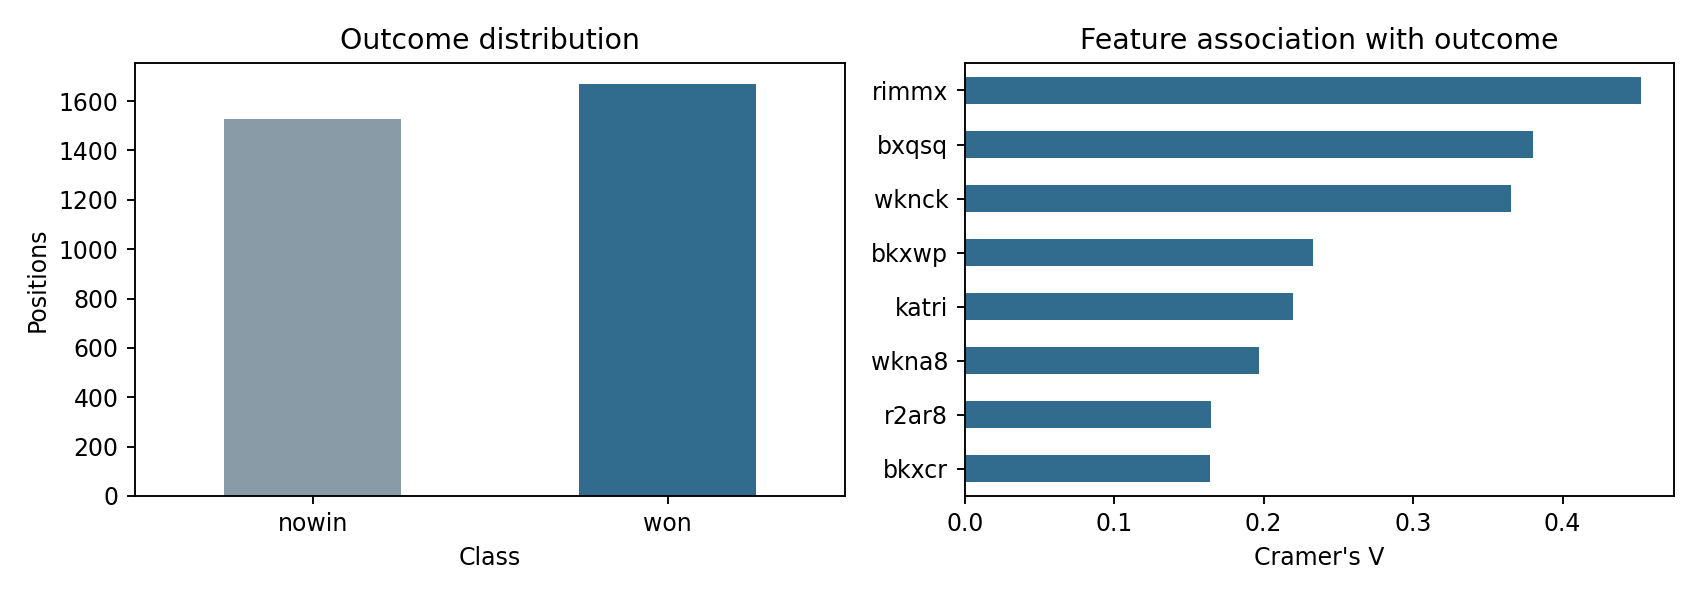

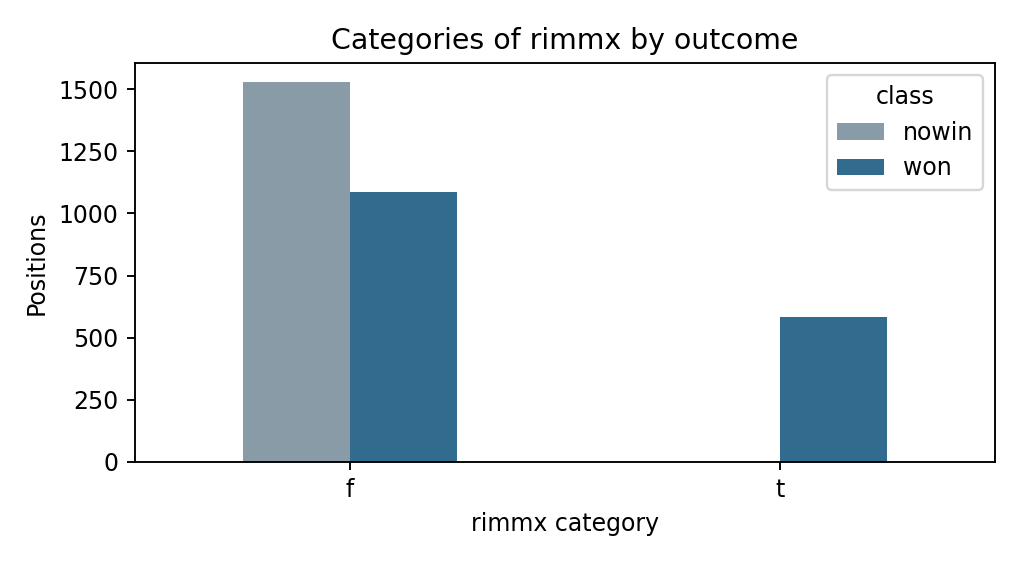

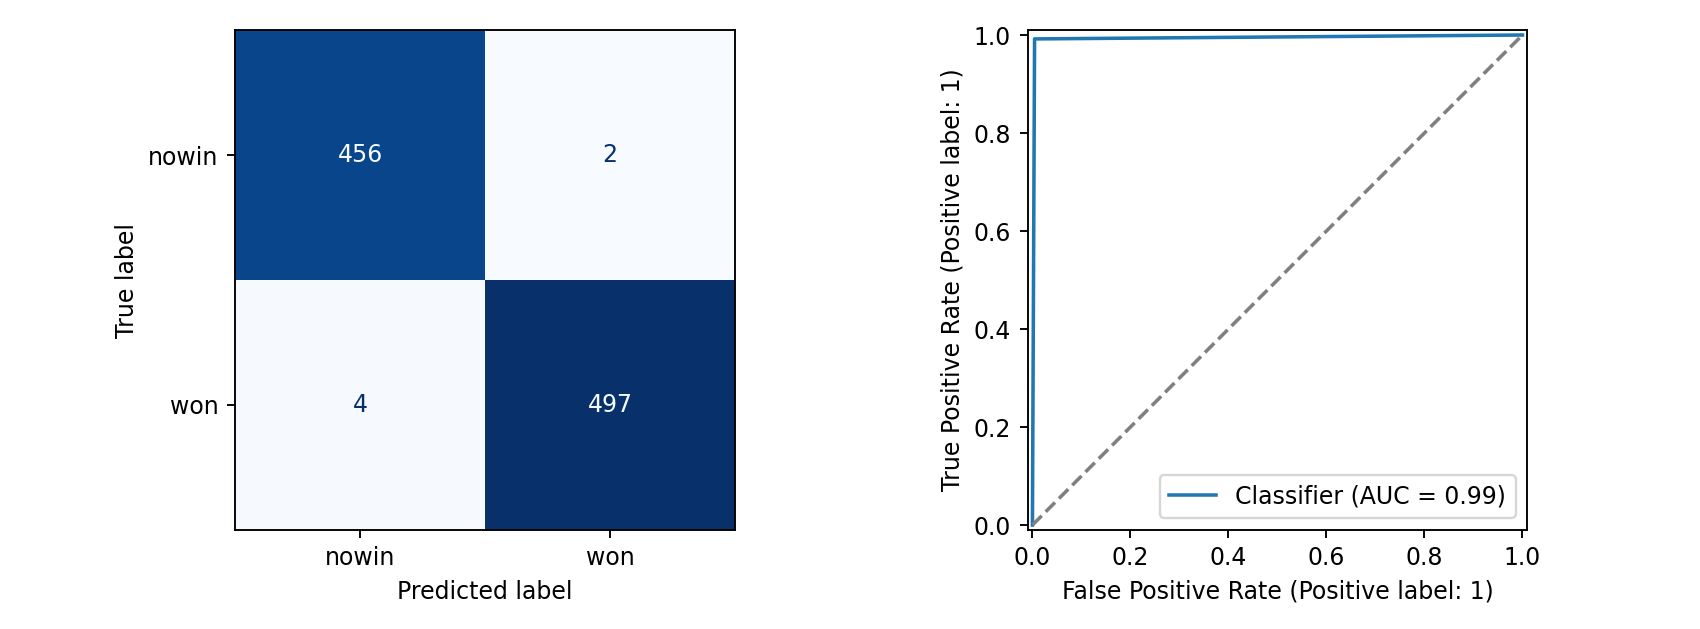

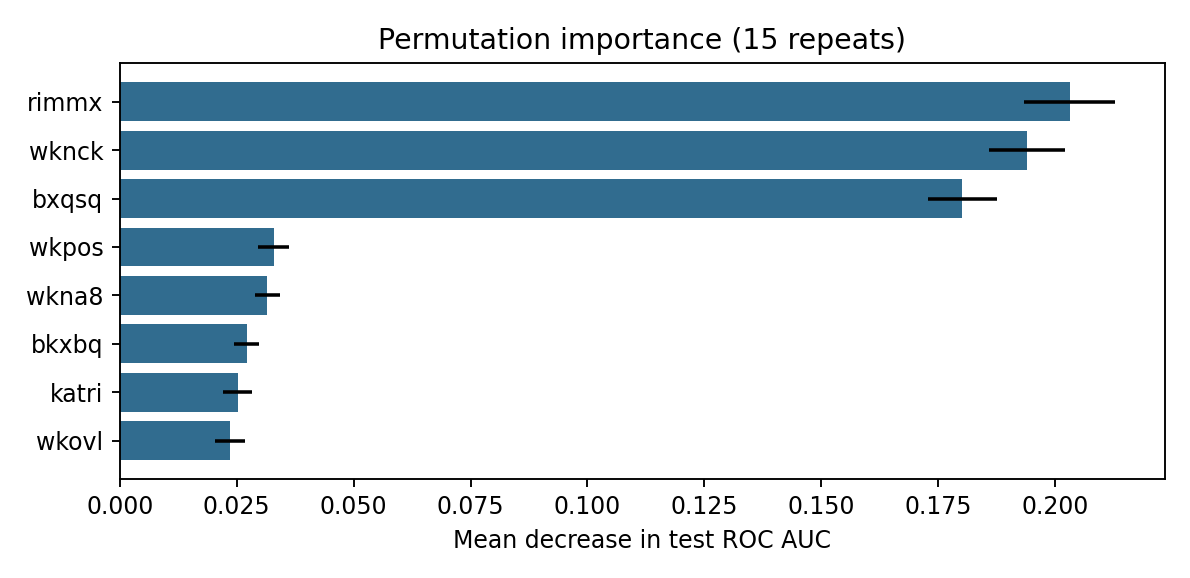

,feature,mean_auc_decrease,sd_auc_decrease
0,rimmx,0.203077,0.009675
1,wknck,0.194035,0.008170
2,bxqsq,0.180177,0.007329
3,wkpos,0.032869,0.003329
4,wkna8,0.031528,0.002698
5,bkxbq,0.027136,0.002693
6,katri,0.025236,0.003136
7,wkovl,0.023497,0.003176
8,bkxcr,0.015647,0.001899
9,bkblk,0.015424,0.001972


In [9]:
from IPython.display import display, Image
r = json.loads((OUT / "results.json").read_text())
display(pd.read_csv(OUT / "model_comparison.csv"))
print("Selected model:", r["selected"])
print("Test metrics:", r["test_metrics"])
print("Class weight comparison:", r["weighting"])
for figure in ["eda.png", "category_distribution.png", "test_results.png", "importance.png"]:
    display(Image(filename=str(OUT / figure)))
display(pd.read_csv(OUT / "permutation_importance.csv").head(10))